# CART-Based Credit Risk Classification

**Student:** Pratik Pattewar  
**Student ID:** 2300030969  
**Programme:** B.Tech – Computer Science and Engineering  
**Institution:** KL University

## Objective
Build and evaluate a Classification and Regression Tree (CART) classifier to classify applicants as **Good** or **Bad** credit risks using the Statlog (German Credit Data) dataset.

> This is an independent implementation using a publicly documented dataset. Review the methodology and explain the results in your own words before submission.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

## 2. Load the dataset

The project uses the **Statlog (German Credit Data)** dataset from the UCI Machine Learning Repository. It contains 1,000 records, 20 applicant attributes and a binary credit-risk target. The original target coding is `1 = Good` and `2 = Bad`.

The loader first checks for a local CSV. If it is not present, it retrieves the dataset through the `ucimlrepo` package and saves a local copy as `data/german_credit.csv`.

In [7]:
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
from pathlib import Path
import pandas as pd
from ucimlrepo import fetch_ucirepo

# Dataset storage location
DATA_PATH = Path("data/german_credit.csv")
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)

# Load existing dataset or download it
if DATA_PATH.exists():
    raw_df = pd.read_csv(DATA_PATH)

    if "Credit_Risk" not in raw_df.columns or len(raw_df) != 1000:
        print("Existing dataset is invalid. Downloading a fresh copy...")
        DATA_PATH.unlink()
        raw_df = None
else:
    raw_df = None

if raw_df is None:
    print("Downloading German Credit dataset from UCI...")

    uci_dataset = fetch_ucirepo(id=144)

    X_uci = uci_dataset.data.features.copy()
    y_uci = uci_dataset.data.targets.copy()

    raw_df = X_uci.reset_index(drop=True)
    raw_df["Credit_Risk"] = y_uci.iloc[:, 0].reset_index(drop=True)

    raw_df.to_csv(DATA_PATH, index=False)

# Final validation
assert raw_df.shape == (1000, 21), "Unexpected dataset dimensions!"
assert "Credit_Risk" in raw_df.columns, "Target column is missing!"
assert raw_df["Credit_Risk"].notna().all(), "Target contains missing values!"

print("Dataset loaded successfully!")
print("Dataset shape:", raw_df.shape)
print("Missing values:", raw_df.isnull().sum().sum())

display(raw_df.head())

Dataset loaded successfully!
Dataset shape: (1000, 21)
Missing values: 0


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,Attribute11,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20,Credit_Risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,2


## 3. Understand and prepare the target

In [9]:
df = raw_df.copy()
target_candidates = [c for c in df.columns if c.lower() in {"class", "credit_risk", "creditability"}]
if not target_candidates:
    target_col = df.columns[-1]
else:
    target_col = target_candidates[0]

# Standardize the target into readable class labels.
target_values = set(pd.Series(df[target_col]).astype(str).str.strip().unique())
mapping = {
    "1": "Good", "1.0": "Good", "good": "Good",
    "2": "Bad", "2.0": "Bad", "bad": "Bad"
}
df["Credit_Risk"] = pd.Series(df[target_col]).astype(str).str.strip().str.lower().map(mapping)

if df["Credit_Risk"].isna().any():
    raise ValueError(
        "Unexpected target labels. Inspect df[target_col].unique() and update mapping."
    )

if target_col != "Credit_Risk":
    df = df.drop(columns=[target_col])

print("Target distribution:")
display(df["Credit_Risk"].value_counts())
print("Missing values:", int(df.isna().sum().sum()))

Target distribution:


Credit_Risk
Good    700
Bad     300
Name: count, dtype: int64

Missing values: 0


## 4. Exploratory data analysis

In [10]:
print("Dataset information:")
df.info()
display(df.describe(include="all").T)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Attribute1   1000 non-null   str  
 1   Attribute2   1000 non-null   int64
 2   Attribute3   1000 non-null   str  
 3   Attribute4   1000 non-null   str  
 4   Attribute5   1000 non-null   int64
 5   Attribute6   1000 non-null   str  
 6   Attribute7   1000 non-null   str  
 7   Attribute8   1000 non-null   int64
 8   Attribute9   1000 non-null   str  
 9   Attribute10  1000 non-null   str  
 10  Attribute11  1000 non-null   int64
 11  Attribute12  1000 non-null   str  
 12  Attribute13  1000 non-null   int64
 13  Attribute14  1000 non-null   str  
 14  Attribute15  1000 non-null   str  
 15  Attribute16  1000 non-null   int64
 16  Attribute17  1000 non-null   str  
 17  Attribute18  1000 non-null   int64
 18  Attribute19  1000 non-null   str  
 19  Attribute20  1000 non-null   str  
 20 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Attribute1,1000,4,A14,394,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attribute2,1000.0,NaN,NaN,NaN,20.903,12.058814,4.0,12.0,18.0,24.0,72.0
Attribute3,1000,5,A32,530,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attribute4,1000,10,A43,280,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attribute5,1000.0,NaN,NaN,NaN,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
Attribute6,1000,5,A61,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attribute7,1000,5,A73,339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attribute8,1000.0,NaN,NaN,NaN,2.973,1.118715,1.0,2.0,3.0,4.0,4.0
Attribute9,1000,4,A93,548,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attribute10,1000,3,A101,907,NaN,NaN,NaN,NaN,NaN,NaN,NaN


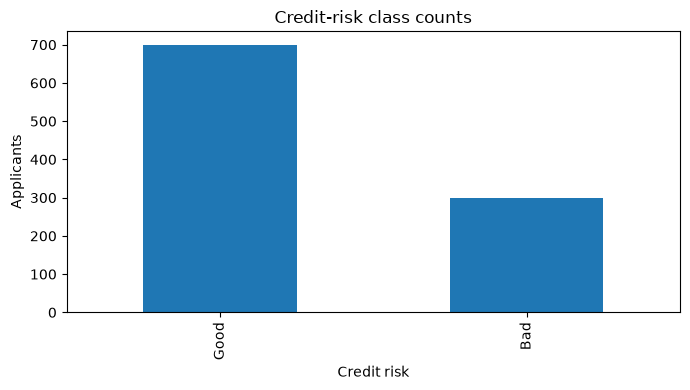

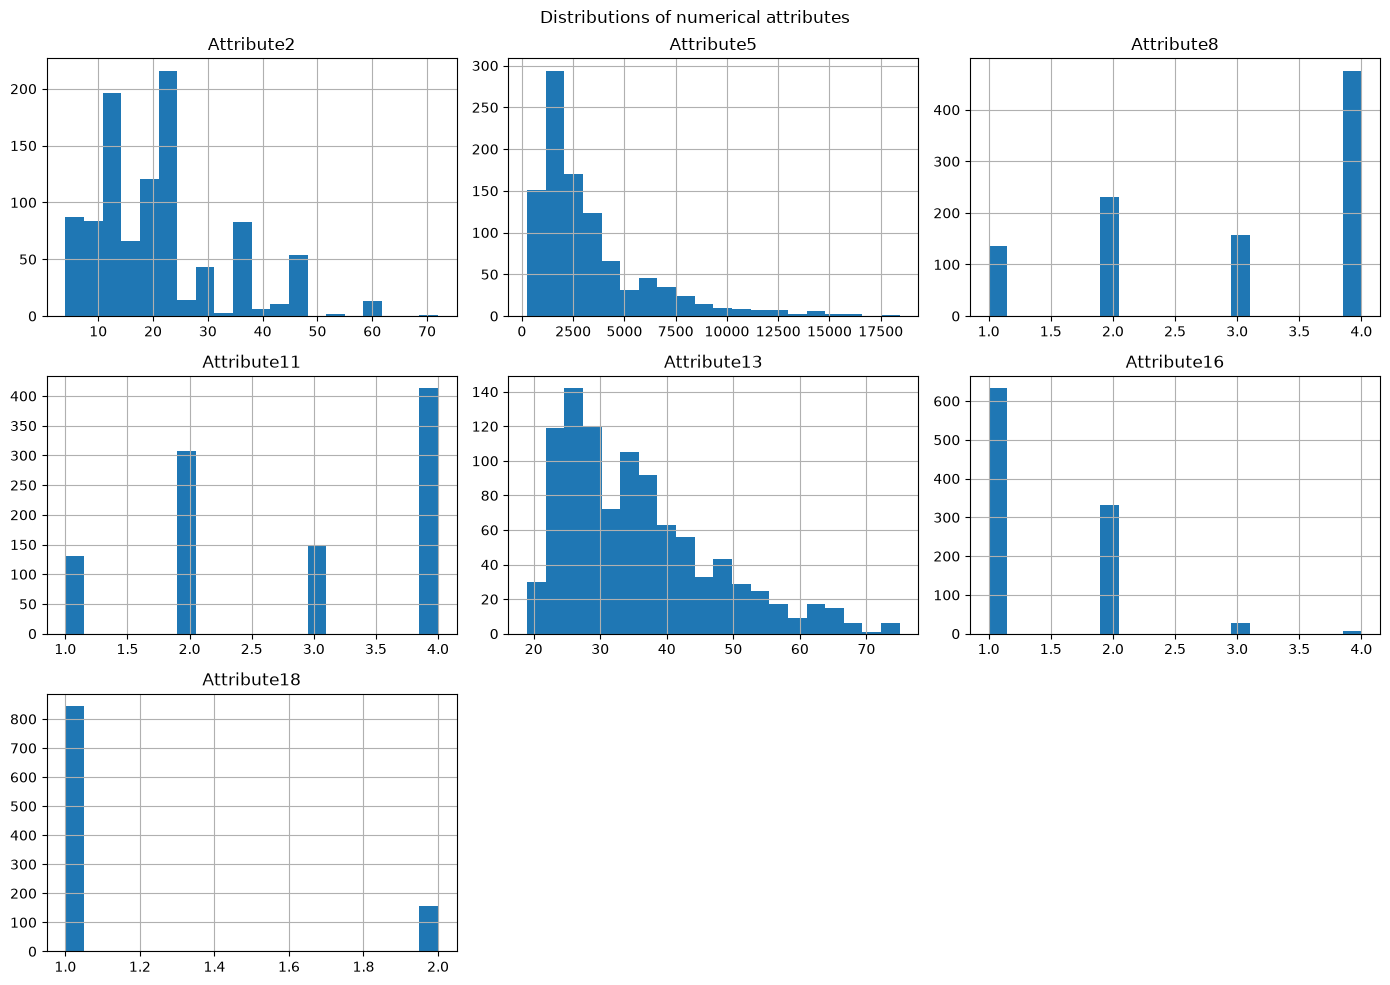

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
df["Credit_Risk"].value_counts().plot(kind="bar", ax=ax, title="Credit-risk class counts")
ax.set_xlabel("Credit risk")
ax.set_ylabel("Applicants")
plt.tight_layout()
plt.show()

numeric_columns = df.select_dtypes(include=np.number).columns
df[numeric_columns].hist(figsize=(14, 10), bins=20)
plt.suptitle("Distributions of numerical attributes")
plt.tight_layout()
plt.show()

## 5. Separate features and target

The target is `Credit_Risk`. All remaining columns are predictor variables. The dataset includes both categorical and numerical attributes, so the preprocessing stage will one-hot encode categorical columns.

In [12]:
X = df.drop(columns="Credit_Risk")
y = df["Credit_Risk"]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Feature matrix:", X.shape)

Numeric features: ['Attribute2', 'Attribute5', 'Attribute8', 'Attribute11', 'Attribute13', 'Attribute16', 'Attribute18']
Categorical features: ['Attribute1', 'Attribute3', 'Attribute4', 'Attribute6', 'Attribute7', 'Attribute9', 'Attribute10', 'Attribute12', 'Attribute14', 'Attribute15', 'Attribute17', 'Attribute19', 'Attribute20']
Feature matrix: (1000, 20)


## 6. Gini impurity

For a node containing classes with proportions \(p_1, p_2, ..., p_k\):

\[
Gini = 1 - \sum_{k=1}^{K} p_k^2
\]

A Gini value of zero indicates a pure node. A binary node has maximum impurity of 0.5 when both classes are equally represented.

In [13]:
def gini_impurity(labels):
    proportions = pd.Series(labels).value_counts(normalize=True)
    return float(1 - np.sum(proportions ** 2))

root_gini = gini_impurity(y)
print(f"Root-node Gini impurity: {root_gini:.4f}")

Root-node Gini impurity: 0.4200


## 7. Calculate weighted child Gini and Gini reduction

For a candidate binary split:

\[
Gini_{split} = \frac{n_L}{n}Gini(L) + \frac{n_R}{n}Gini(R)
\]

\[
Gini\ Reduction = Gini(parent) - Gini_{split}
\]

The manual split demonstration below searches midpoint thresholds for numerical attributes. It is an illustrative one-level split analysis; the fitted scikit-learn CART model subsequently searches its encoded feature space.

In [14]:
def score_binary_split(mask, labels):
    mask = np.asarray(mask, dtype=bool)
    left, right = np.asarray(labels)[mask], np.asarray(labels)[~mask]
    if len(left) == 0 or len(right) == 0:
        return None
    weighted = (len(left) / len(labels)) * gini_impurity(left) + (len(right) / len(labels)) * gini_impurity(right)
    return {
        "Left samples": len(left),
        "Right samples": len(right),
        "Weighted child Gini": weighted,
        "Gini reduction": gini_impurity(labels) - weighted
    }

manual_splits = []
for feature in numeric_features:
    values = np.sort(X[feature].dropna().unique())
    if len(values) < 2:
        continue
    thresholds = (values[:-1] + values[1:]) / 2
    for threshold in thresholds:
        result = score_binary_split(X[feature].to_numpy() <= threshold, y.to_numpy())
        if result:
            manual_splits.append({"Feature": feature, "Threshold": threshold, **result})

manual_split_table = pd.DataFrame(manual_splits).sort_values(
    "Gini reduction", ascending=False
).reset_index(drop=True)
display(manual_split_table.head(10))

,Feature,Threshold,Left samples,Right samples,Weighted child Gini,Gini reduction
0,Attribute2,34.5,830,170,0.406378,0.013622
1,Attribute2,31.5,827,173,0.406479,0.013521
2,Attribute2,15.5,431,569,0.406755,0.013245
3,Attribute2,17.0,433,567,0.407031,0.012969
4,Attribute2,26.5,771,229,0.407439,0.012561
5,Attribute2,25.0,770,230,0.407702,0.012298
6,Attribute2,29.0,787,213,0.407706,0.012294
7,Attribute2,27.5,784,216,0.407755,0.012245
8,Attribute5,3913.5,740,260,0.408680,0.011320
9,Attribute2,43.5,930,70,0.408909,0.011091


## 8. Split data into training and testing sets

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).rename("Proportion"))
print("\nTesting class proportions:")
display(y_test.value_counts(normalize=True).rename("Proportion"))

Training rows: 800
Testing rows: 200

Training class proportions:


Credit_Risk
Good    0.7
Bad     0.3
Name: Proportion, dtype: float64


Testing class proportions:


Credit_Risk
Good    0.7
Bad     0.3
Name: Proportion, dtype: float64

## 9. Encode categorical features

Decision trees in scikit-learn require numeric input. Numerical features are passed through unchanged and categorical features are one-hot encoded. The preprocessing transformer is fitted only on the training partition through a pipeline, preventing information leakage.

In [16]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numerical", "passthrough", numeric_features)
    ],
    remainder="drop"
)

## 10. Train the CART classifier

`criterion="gini"` selects splits using Gini impurity. `max_depth` and `min_samples_leaf` constrain tree complexity to reduce overfitting. The values are transparent modelling choices and can be adjusted during experimentation.

In [17]:
cart_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        min_samples_leaf=10,
        random_state=RANDOM_STATE
    ))
])

cart_pipeline.fit(X_train, y_train)
tree_model = cart_pipeline.named_steps["classifier"]
feature_names = cart_pipeline.named_steps["preprocessor"].get_feature_names_out()

print("CART model trained successfully.")
print("Tree depth:", tree_model.get_depth())
print("Number of leaves:", tree_model.get_n_leaves())

CART model trained successfully.
Tree depth: 5
Number of leaves: 22


## 11. Generate predictions

In [18]:
y_pred = cart_pipeline.predict(X_test)
results = X_test.copy()
results["Actual_Risk"] = y_test
results["Predicted_Risk"] = y_pred
results["Correct"] = results["Actual_Risk"] == results["Predicted_Risk"]
display(results.head(15))

,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,Attribute11,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20,Actual_Risk,Predicted_Risk,Correct
977,A12,18,A33,A49,2427,A65,A75,4,A93,A101,2,A122,42,A143,A152,2,A173,1,A191,A201,Good,Good,True
735,A12,36,A31,A44,3990,A65,A72,3,A92,A101,2,A124,29,A141,A152,1,A171,1,A191,A201,Good,Good,True
615,A12,48,A30,A49,12204,A65,A73,2,A93,A101,2,A123,48,A141,A152,1,A174,1,A192,A201,Good,Good,True
413,A14,10,A32,A40,1597,A63,A73,3,A93,A101,2,A124,40,A143,A151,1,A172,2,A191,A202,Good,Good,True
563,A12,36,A32,A40,12389,A65,A73,1,A93,A101,4,A124,37,A143,A153,1,A173,1,A192,A201,Bad,Good,False
27,A13,12,A31,A43,409,A64,A73,3,A92,A101,3,A121,42,A143,A151,2,A173,1,A191,A201,Good,Good,True
514,A14,24,A32,A40,2255,A65,A72,4,A93,A101,1,A122,54,A143,A152,1,A173,1,A191,A201,Good,Good,True
624,A11,18,A32,A43,2600,A61,A73,4,A93,A101,4,A124,65,A143,A153,2,A173,1,A191,A201,Bad,Good,False
475,A11,18,A30,A42,3114,A61,A72,1,A92,A101,4,A122,26,A143,A151,1,A173,1,A191,A201,Bad,Good,False
991,A14,15,A31,A43,1569,A62,A75,4,A93,A101,4,A123,34,A141,A152,1,A172,2,A191,A201,Good,Good,True


## 12. Evaluate model performance

In [19]:
train_predictions = cart_pipeline.predict(X_train)
metrics = {
    "Training accuracy": accuracy_score(y_train, train_predictions),
    "Testing accuracy": accuracy_score(y_test, y_pred),
    "Precision (Bad class)": precision_score(y_test, y_pred, pos_label="Bad", zero_division=0),
    "Recall (Bad class)": recall_score(y_test, y_pred, pos_label="Bad", zero_division=0),
    "F1-score (Bad class)": f1_score(y_test, y_pred, pos_label="Bad", zero_division=0)
}
display(pd.Series(metrics, name="Score").to_frame())
print(classification_report(y_test, y_pred, zero_division=0))

,Score
Training accuracy,0.763750
Testing accuracy,0.710000
Precision (Bad class),0.555556
Recall (Bad class),0.166667
F1-score (Bad class),0.256410


              precision    recall  f1-score   support

         Bad       0.56      0.17      0.26        60
        Good       0.73      0.94      0.82       140

    accuracy                           0.71       200
   macro avg       0.64      0.55      0.54       200
weighted avg       0.67      0.71      0.65       200



## 13. Confusion matrix

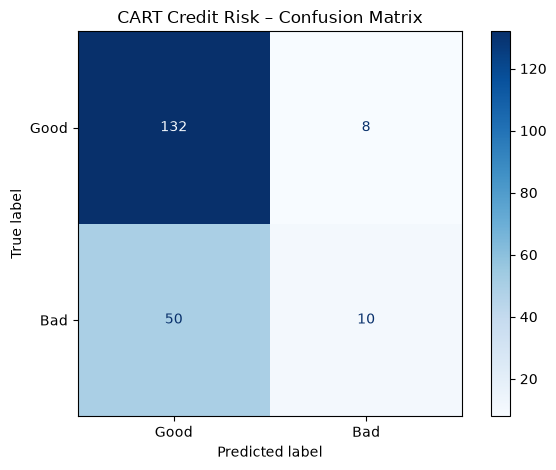

In [20]:
labels = ["Good", "Bad"]
cm = confusion_matrix(y_test, y_pred, labels=labels)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(cmap="Blues")
plt.title("CART Credit Risk – Confusion Matrix")
plt.tight_layout()
plt.show()

## 14. Visualize the decision tree

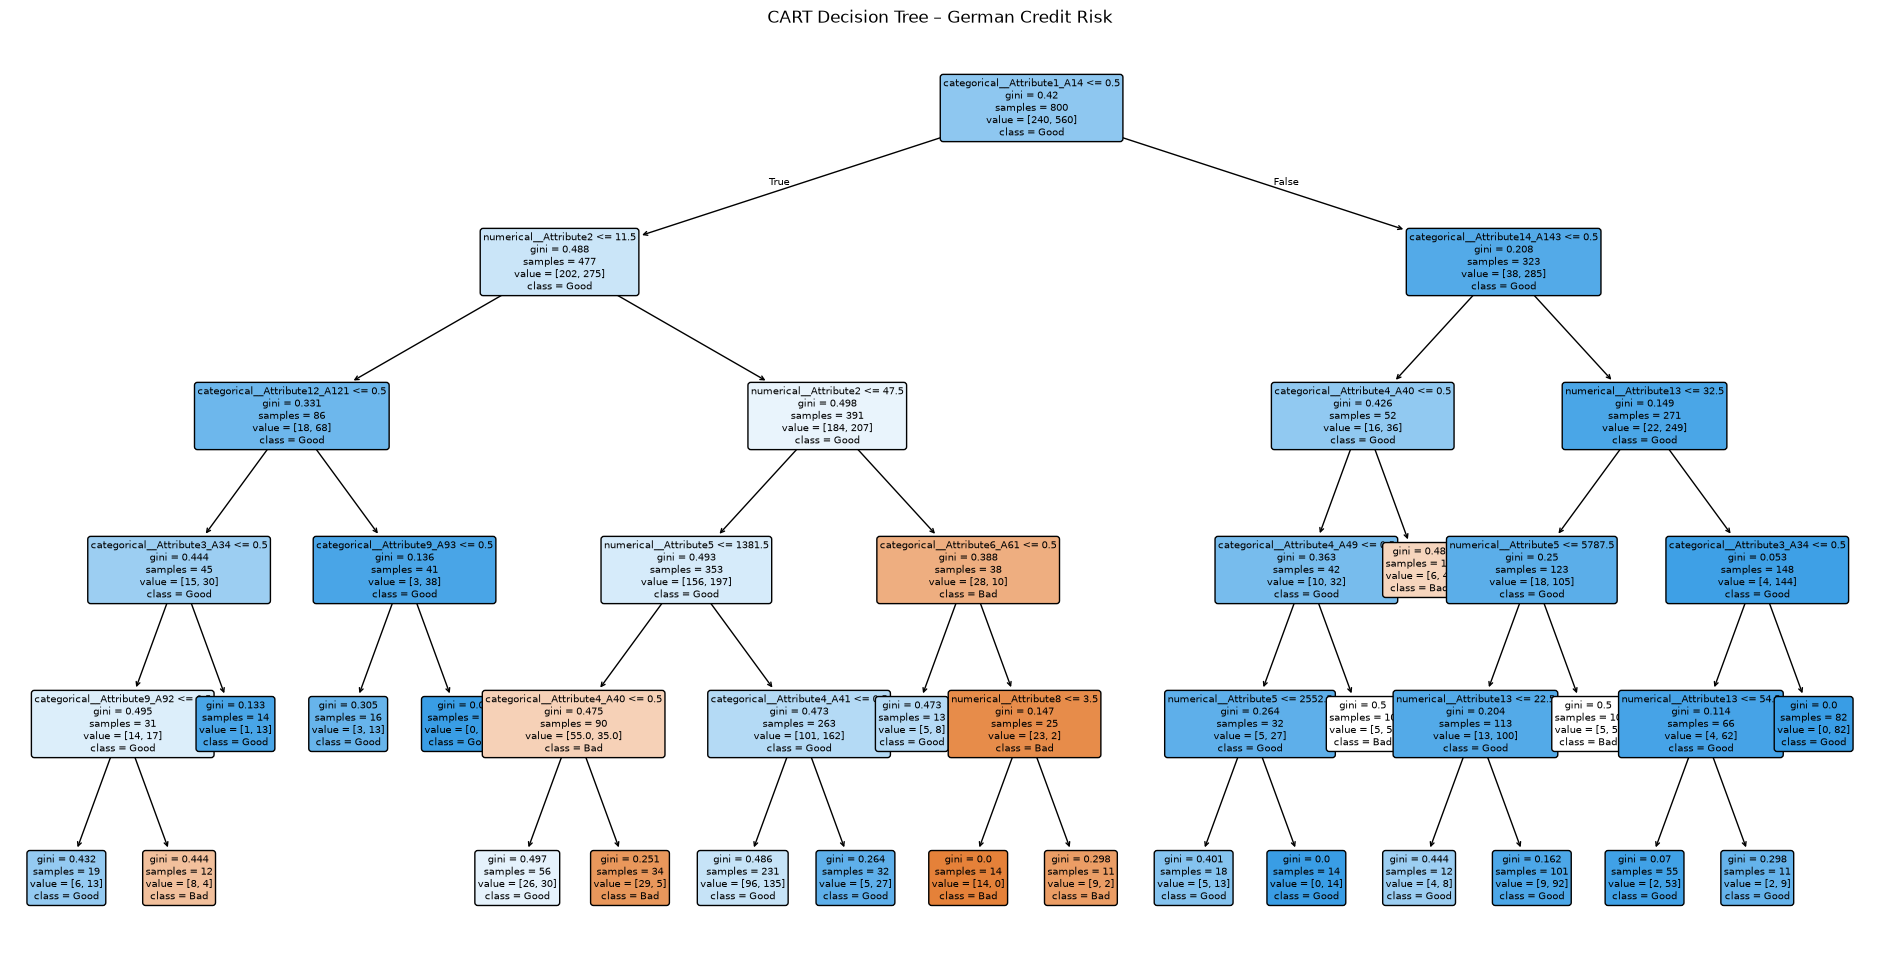

|--- categorical__Attribute1_A14 <= 0.50
|   |--- numerical__Attribute2 <= 11.50
|   |   |--- categorical__Attribute12_A121 <= 0.50
|   |   |   |--- categorical__Attribute3_A34 <= 0.50
|   |   |   |   |--- categorical__Attribute9_A92 <= 0.50
|   |   |   |   |   |--- class: Good
|   |   |   |   |--- categorical__Attribute9_A92 >  0.50
|   |   |   |   |   |--- class: Bad
|   |   |   |--- categorical__Attribute3_A34 >  0.50
|   |   |   |   |--- class: Good
|   |   |--- categorical__Attribute12_A121 >  0.50
|   |   |   |--- categorical__Attribute9_A93 <= 0.50
|   |   |   |   |--- class: Good
|   |   |   |--- categorical__Attribute9_A93 >  0.50
|   |   |   |   |--- class: Good
|   |--- numerical__Attribute2 >  11.50
|   |   |--- numerical__Attribute2 <= 47.50
|   |   |   |--- numerical__Attribute5 <= 1381.50
|   |   |   |   |--- categorical__Attribute4_A40 <= 0.50
|   |   |   |   |   |--- class: Good
|   |   |   |   |--- categorical__Attribute4_A40 >  0.50
|   |   |   |   |   |--- class: Ba

In [21]:
plt.figure(figsize=(24, 12))
plot_tree(
    tree_model,
    feature_names=list(feature_names),
    class_names=list(tree_model.classes_),
    filled=True,
    rounded=True,
    fontsize=7
)
plt.title("CART Decision Tree – German Credit Risk")
plt.show()

print(export_text(tree_model, feature_names=list(feature_names), max_depth=5))

## 15. Feature importance

,Gini importance
categorical__Attribute1_A14,0.366179
numerical__Attribute2,0.158488
numerical__Attribute5,0.110315
categorical__Attribute4_A40,0.086465
categorical__Attribute6_A61,0.049834
categorical__Attribute14_A143,0.045503
categorical__Attribute4_A41,0.038426
numerical__Attribute13,0.036386
categorical__Attribute3_A34,0.031068
categorical__Attribute12_A121,0.029518


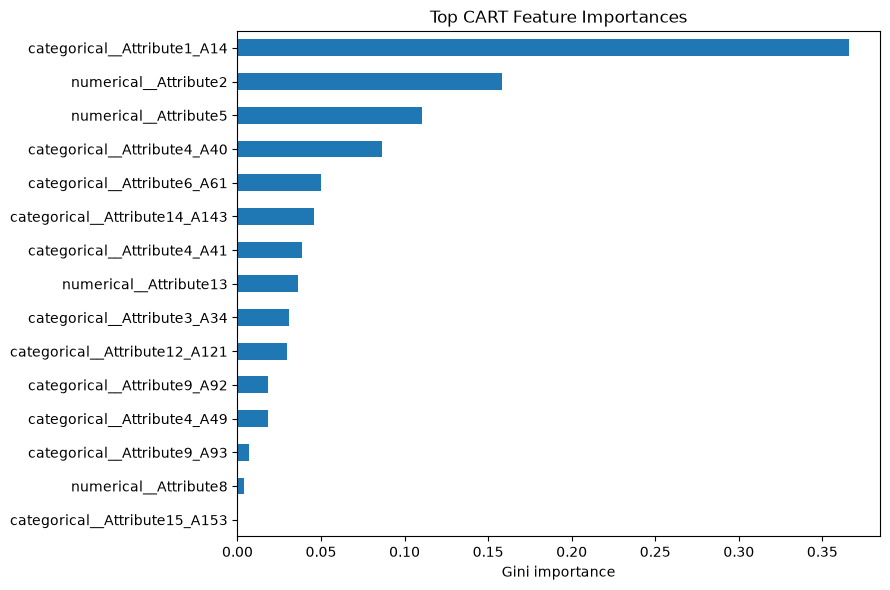

In [22]:
importance = pd.Series(tree_model.feature_importances_, index=feature_names)
importance = importance.sort_values(ascending=False)
display(importance.head(15).to_frame("Gini importance"))

importance.head(15).sort_values().plot(kind="barh", figsize=(9, 6))
plt.xlabel("Gini importance")
plt.title("Top CART Feature Importances")
plt.tight_layout()
plt.show()

## 16. Example prediction for a new applicant

The example below uses one existing row as a schema-safe demonstration. Replace its values with a new applicant profile when experimenting. This model is for coursework demonstration only, not real lending decisions.

In [23]:
sample_applicant = X_test.iloc[[0]].copy()
sample_prediction = cart_pipeline.predict(sample_applicant)[0]
print("Example applicant:")
display(sample_applicant)
print("Predicted credit-risk class:", sample_prediction)

Example applicant:


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,Attribute11,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20
977,A12,18,A33,A49,2427,A65,A75,4,A93,A101,2,A122,42,A143,A152,2,A173,1,A191,A201


Predicted credit-risk class: Good


## 17. Interpretation, limitations and conclusion

- CART is a supervised learning algorithm that recursively divides the feature space into binary regions.
- Gini impurity measures class mixing at each node; a split is useful when it reduces weighted child impurity.
- The preprocessing pipeline converts categorical attributes into numeric indicators while leaving numeric features unscaled.
- Accuracy should be interpreted alongside precision, recall, F1-score and the confusion matrix, especially because the dataset's class distribution is imbalanced.
- The original UCI documentation supplies a cost matrix that treats classifying a bad-risk applicant as good as more costly than the reverse. The default CART objective here does not directly optimize that cost matrix.
- This historical dataset may not represent present-day applicants or lending practices. It should not be used for actual credit decisions.

**Conclusion:** The project demonstrates data exploration, manual Gini calculations, categorical preprocessing, CART model training, prediction, evaluation and tree interpretation on a public credit-risk classification dataset.

## Dataset citation

Hofmann, H. (1994). *Statlog (German Credit Data)* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5NC77

Dataset page: https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data  
License: Creative Commons Attribution 4.0 International (CC BY 4.0).